# Estrategia de validación y selección de modelo

El producto estima el caudal diario de cuencas colombianas, **también donde no hay estación**. Por lo que se definen dos preguntas de evaluación, cada una con su propia partición y KPIs:

| Pregunta | Partición | KPI del primer reporte |
|---|---|---|
| ¿Qué tan bien estima días futuros de cuencas que el modelo ya vio? | **Temporal**: 60/20/20 cronológico dentro de cada cuenca | P4: NSE y KGE medianos ≥ 0,70 |
| ¿Sirve en cuencas que nunca vio (sin estación)? | **Espacial**: 5 folds de cuencas completas, sin separar cuencas anidadas | P6: NSE mediano ≥ 0,50 |

**Entradas.** Las filas preparadas en `preparacion_datos.ipynb`, compuestas por 248 cuencas, un día por fila, caudal específico $q$ [mm/día] como objetivo y sin caudal de días anteriores como entrada. Funciones: `codigo/preparar_datos.py` (filas, partición temporal, métricas) y `codigo/validacion.py` (cuencas anidadas, folds, distribuciones, selección).

**Fuentes externas.** [1] Roberts et al., *Cross-validation strategies for data with temporal, spatial, hierarchical, or phylogenetic structure*, Ecography 40, 2017. [2] Kratzert et al., *Toward improved predictions in ungauged basins: exploiting the power of machine learning*, Water Resour. Res. 55, 2019. [3] Siddiqi, *Credit Risk Scorecards*, Wiley, 2006 (índice de estabilidad poblacional). [4] Nash y Sutcliffe, J. Hydrol. 10, 1970; Gupta et al., J. Hydrol. 377, 2009 (NSE y KGE).

| Sección | Qué se hace |
|---|---|
| 1 | Por qué no se parte al azar (autocorrelación y un experimento) |
| 2 | Partición temporal: por qué no la fecha fija del primer reporte y cómo queda |
| 3 | Validación cruzada espacial: cuencas anidadas, folds y cobertura residual |
| 4 | Verificación de que las distribuciones se conservan (temporal y espacial) |
| 5 | Estrategia de selección del modelo y línea base con el protocolo |
| 6 | Archivos para el modelado |
| 7 | Lo que pide el ítem 9 y limitaciones |

## 0. Configuración del entorno

In [1]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "codigo"))
import preparar_datos as pdat
import validacion as val

OUT = val.SALIDA; OUT.mkdir(parents=True, exist_ok=True)
ORDEN = ["Magdalena-Cauca", "Orinoco", "Caribe", "Pacífico", "Amazonas"]
COLOR = {"Magdalena-Cauca": "#2a78d6", "Caribe": "#eb6834", "Orinoco": "#1baf7a", "Pacífico": "#eda100", "Amazonas": "#e87ba4"}
COLOR_P = {"entrenamiento": "#2a78d6", "validacion": "#eda100", "prueba": "#d62728"}
for p in ("salidas/cuencas_modelado.csv", "salidas/series_limpias"):
    assert (RAIZ / p).exists(), f"Falta {p}: ejecute `python codigo/limpiar_series.py` y `python codigo/aplicar_banderas.py`"

est = pdat.atributos_estaticos()
areas = pdat.areas_cuencas(est.index)
region = est.region
filas, resumen = pdat.construir_filas(est, areas)
filas["particion"] = pd.Categorical(filas.particion, categories=val.PERIODOS)
filas["region"] = filas.gauge_id.map(region)
print(f"{len(est)} cuencas, {len(filas):,} filas utilizables")

248 cuencas, 2,483,808 filas utilizables


## 1. Por qué no se parte al azar
La forma más sencilla de dividir los datos es aleatoriamente, sin embargo, en este dominio específico no es posible.

La validación cruzada con mezcla aleatoria supone que las filas son independientes. En una serie de caudal no lo son porque el caudal de hoy se parece al de ayer. Si los días se reparten al azar, cada día de evaluación tiene a sus vecinos en el entrenamiento y el modelo parece mejor de lo que es [1].

### 1a. Autocorrelación del caudal
Para cada cuenca se calcula la correlación entre $q(t)$ y $q(t-k)$ y se resume con la mediana entre cuencas.

rezago [días],1,2,3,5,7,10,15,20,30,60,90
mediana,0.804,0.711,0.648,0.576,0.529,0.486,0.440,0.395,0.323,0.153,0.024
p10,0.560,0.438,0.376,0.336,0.292,0.258,0.223,0.203,0.163,0.019,-0.071
p90,0.973,0.941,0.918,0.867,0.825,0.784,0.726,0.679,0.587,0.328,0.142


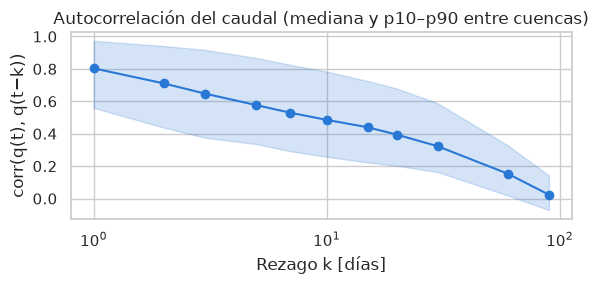

In [2]:
REZAGOS = [1, 2, 3, 5, 7, 10, 15, 20, 30, 60, 90]

def autocorrelacion(d):
    s = d.set_index("Fecha").q.asfreq("D")
    return pd.Series({k: s.autocorr(k) for k in REZAGOS})

ac = filas.groupby("gauge_id")[["Fecha", "q"]].apply(autocorrelacion)
tac = pd.DataFrame({"mediana": ac.median(), "p10": ac.quantile(.1), "p90": ac.quantile(.9)}).rename_axis("rezago [días]")
display(tac.round(3).T)
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(REZAGOS, tac.mediana, "o-", color="#2a78d6"); ax.fill_between(REZAGOS, tac.p10, tac.p90, alpha=.2, color="#2a78d6")
ax.set(xscale="log", xlabel="Rezago k [días]", ylabel="corr(q(t), q(t−k))", title="Autocorrelación del caudal (mediana y p10–p90 entre cuencas)")
fig.tight_layout(); fig.savefig(OUT / "fig_autocorrelacion.png", dpi=200); plt.show()

### 1b. Experimento: partición aleatoria contra cronológica
Se utiliza un mismo modelo (Random Forest de 60 árboles), mismas 40 cuencas tomadas al azar y mismo número de días de evaluación. Solo cambia cómo se escogen esos días: **al azar** entre todos los días, o **el bloque final** de cada cuenca. 

Es importante aclarar que se usan solo los periodos de entrenamiento y validación; la prueba no se toca.

In [3]:
col_num, col_cat = pdat.columnas(est)
COLS = col_num + col_cat
X = pdat.agregar_estaticos(filas.drop(columns="region"), est)

rng = np.random.default_rng(0)
d40 = X[X.gauge_id.isin(rng.choice(est.index, 40, replace=False)) & (X.particion != "prueba")]
rf = Pipeline([("pre", pdat.crear_preprocesamiento(col_num, col_cat)),
               ("modelo", RandomForestRegressor(n_estimators=60, min_samples_leaf=5, max_features=0.33, n_jobs=-1, random_state=0))])
ev_crono = d40[d40.particion == "validacion"]
ev_azar = d40.sample(n=len(ev_crono), random_state=0)
exp = {}
for nombre, ev in (("cronológica (bloque final)", ev_crono), ("aleatoria (días sueltos)", ev_azar)):
    tr = d40.drop(index=ev.index)
    rf.fit(tr[COLS], tr.q)
    exp[nombre] = pdat.metricas_por_cuenca(ev.gauge_id, ev.q, rf.predict(ev[COLS]))
texp = pd.DataFrame({k: v[["NSE", "KGE", "RMSE"]].median() for k, v in exp.items()}).T
texp["cuencas con NSE mejor que en la cronológica"] = ["—", int(exp["aleatoria (días sueltos)"].NSE.gt(exp["cronológica (bloque final)"].NSE).sum())]
print(f"{len(d40):,} filas de 40 cuencas, {len(ev_crono):,} días de evaluación en cada caso")
display(texp.round(3))

330,147 filas de 40 cuencas, 75,157 días de evaluación en cada caso


,NSE,KGE,RMSE,cuencas con NSE mejor que en la cronológica
cronológica (bloque final),0.413,0.522,1.605,—
aleatoria (días sueltos),0.604,0.645,1.395,39


**Lectura.** El caudal tiene mucha memoria: la autocorrelación mediana es 0,80 con un día de rezago, 0,53 a una semana y todavía 0,32 a un mes. Con la partición aleatoria el mismo Random Forest pasa de un NSE mediano de 0,41 a 0,60, y 39 de las 40 cuencas mejoran: **la mezcla aleatoria infla el NSE en casi 0,2** porque el modelo reconoce días casi iguales a los que vio. Por eso no se usa `KFold` con mezcla ni `train_test_split` sobre filas: todas las particiones de este notebook respetan el orden del tiempo o separan cuencas completas.

## 2. Partición temporal

### 2a. Por qué no la fecha fija del primer reporte
El primer reporte proponía entrenamiento 1981–2010, validación 2011–2015 y prueba 2016–2022. Se cuenta cuántas cuencas tienen menos de un año de caudal válido en un periodo de prueba que empiece en distintos años y termine en 2022.

inicio de la prueba,2008,2009,2010,2011,2012,2013,2014,2015,2016
cuencas con < 1 año de caudal válido,28,31,34,41,45,47,52,59,61
cuencas sin ningún día,27,28,29,35,41,43,48,52,59


Última fecha con caudal válido: mediana 2021-11; 59 cuencas terminan antes de 2016


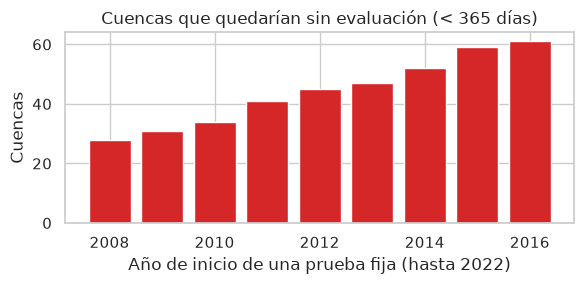

In [4]:
ok = {}
for g in est.index:
    s = pd.read_csv(pdat.SERIES / f"Hydromet_data_{g}.txt", sep="\t", usecols=["Fecha", "Caudal_estado"])
    ok[g] = pd.to_datetime(s.Fecha[s.Caudal_estado == "ok"], format="%d/%m/%Y")
INICIOS = range(2008, 2017)
tfija = pd.DataFrame([{"inicio de la prueba": a,
                       "cuencas con < 1 año de caudal válido": sum(int((f >= f"{a}-01-01").sum()) < 365 for f in ok.values()),
                       "cuencas sin ningún día": sum(int((f >= f"{a}-01-01").sum()) == 0 for f in ok.values())} for a in INICIOS]).set_index("inicio de la prueba")
fin = pd.Series({g: f.max() for g, f in ok.items()})
display(tfija.T)
print(f"Última fecha con caudal válido: mediana {fin.median():%Y-%m}; {int((fin < '2016-01-01').sum())} cuencas terminan antes de 2016")
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(tfija.index, tfija.iloc[:, 0], color="#d62728"); ax.axhline(0, color="#555", lw=.6)
ax.set(xlabel="Año de inicio de una prueba fija (hasta 2022)", ylabel="Cuencas", title="Cuencas que quedarían sin evaluación (< 365 días)")
fig.tight_layout(); fig.savefig(OUT / "fig_prueba_fecha_fija.png", dpi=200); plt.show()

**Lectura.** Con la prueba en 2016–2022, **61 de las 248 cuencas (25 %) tendrían menos de un año de caudal válido** para evaluar, porque muchas estaciones dejaron de medir antes (59 cuencas no tienen caudal válido después de 2015). Adelantar la fecha no lo arregla: desde 2010 todavía quedan 34. Con una fecha fija, el KPI de prueba se calcularía sobre las cuencas que siguen midiendo, que no representan al país.

**Decisión.** Se cambia a una partición **cronológica dentro de cada cuenca**: el primer 60 % de sus días con caudal válido es entrenamiento, el 20 % siguiente validación y el 20 % final prueba (`pdat.filas_cuenca`). Así las 248 cuencas aparecen en los tres conjuntos y la prueba es siempre el futuro de lo que el modelo vio. El 60/20/20 es la proporción usada en la Práctica 6. Esto **corrige lo dicho en el primer reporte** y debe quedar así en el informe final.

### 2b. La partición resultante

,filas,% de las filas,cuencas,días por cuenca (mediana)
particion,,,,
entrenamiento,1566789,63.1,248,6807.0
validacion,456597,18.4,248,1898.5
prueba,460422,18.5,248,2000.5


,p10,mediana,p90
inicio de validación,1996-03,2005-07,2008-10
inicio de prueba,2001-10,2013-09,2015-11


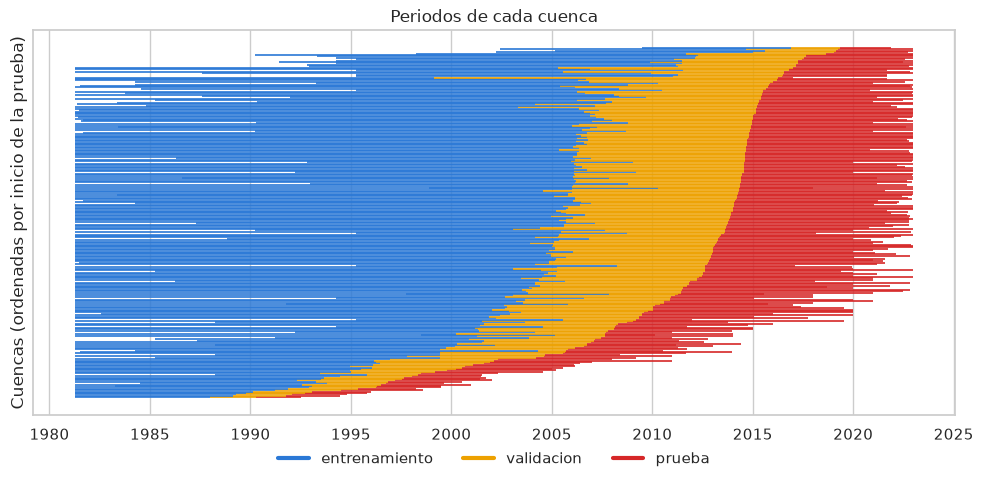

In [5]:
fc = val.fechas_corte(filas)
tp = pd.DataFrame({"filas": filas.particion.value_counts().reindex(val.PERIODOS)})
tp["% de las filas"] = 100 * tp.filas / tp.filas.sum()
tp["cuencas"] = [filas.loc[filas.particion == p, "gauge_id"].nunique() for p in val.PERIODOS]
tp["días por cuenca (mediana)"] = [fc[f"filas_{p}"].median() for p in val.PERIODOS]
display(tp.round(1))
display(pd.DataFrame({"inicio de validación": fc.inicio_validacion.quantile([.1, .5, .9]).dt.strftime("%Y-%m").values,
                      "inicio de prueba": fc.inicio_prueba.quantile([.1, .5, .9]).dt.strftime("%Y-%m").values},
                     index=["p10", "mediana", "p90"]).T)

orden = fc.sort_values("inicio_prueba").index
fig, ax = plt.subplots(figsize=(10, 5))
for i, g in enumerate(orden):
    f = fc.loc[g]
    ax.hlines(i, f.inicio_entrenamiento, f.inicio_validacion, color=COLOR_P["entrenamiento"], lw=1.2)
    ax.hlines(i, f.inicio_validacion, f.inicio_prueba, color=COLOR_P["validacion"], lw=1.2)
    ax.hlines(i, f.inicio_prueba, f.fin_prueba, color=COLOR_P["prueba"], lw=1.2)
for p, c in COLOR_P.items(): ax.plot([], [], color=c, lw=3, label=p)
ax.set(ylabel="Cuencas (ordenadas por inicio de la prueba)", yticks=[], title="Periodos de cada cuenca")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(.5, -.06), ncol=3)
fig.tight_layout(); fig.savefig(OUT / "fig_particion_temporal.png", dpi=200); plt.show()

**Lectura.** Las filas quedan en 63 / 18 / 18 % y no en 60/20/20 exacto. El corte se hace sobre los días con caudal válido, y después se pierden las filas cuya ventana de lluvia tiene huecos, que pesan más en validación y prueba. Las 248 cuencas tienen días en los tres conjuntos, con una mediana de unos 1.900 a 2.000 días (más de cinco años) de validación y de prueba por cuenca. Para la cuenca mediana la validación empieza en 2005 y la prueba en septiembre de 2013.

**Limitación que va al informe.** Como cada cuenca se corta en su propia fecha, la prueba no es el mismo periodo del calendario para todas: empieza en 2001 o antes en el 10 % de las cuencas y después de noviembre de 2015 en otro 10 %. El KPI de prueba mezcla épocas climáticas distintas. A cambio, todas las cuencas se evalúan.

## 3. Validación cruzada espacial (cuencas sin estación)
La partición temporal no responde P6 pues todas las cuencas de prueba también están en el entrenamiento. Para estimar el desempeño en una cuenca sin estación hay que **dejar cuencas completas por fuera** [2]. Se usan 5 folds: cada cuenca se evalúa una vez con un modelo que nunca la vio.

El riesgo son las **cuencas anidadas**: si una estación está aguas abajo de otra, gran parte de su caudal viene de la de arriba. Si una queda en entrenamiento y la otra en evaluación, el modelo ya vio buena parte de la respuesta y el resultado sale optimista [1].

### 3a. Cuencas anidadas
La relación de anidamiento no viene en el dataset, pero se calcula con los polígonos de CAMELS-COL: para cada par de cuencas que se tocan, qué fracción del área de la pequeña está dentro de la grande.

Pares de cuencas que se tocan: 2,541   anidadas (> 50 % dentro): 1,044   cuencas que contienen o están dentro de otra: 229 de 248
Pares con solapamiento parcial (1 %–95 %): 0
Si se agrupa toda cuenca conectada: 35 grupos; el mayor tiene 130 cuencas ({'Magdalena-Cauca': 130})


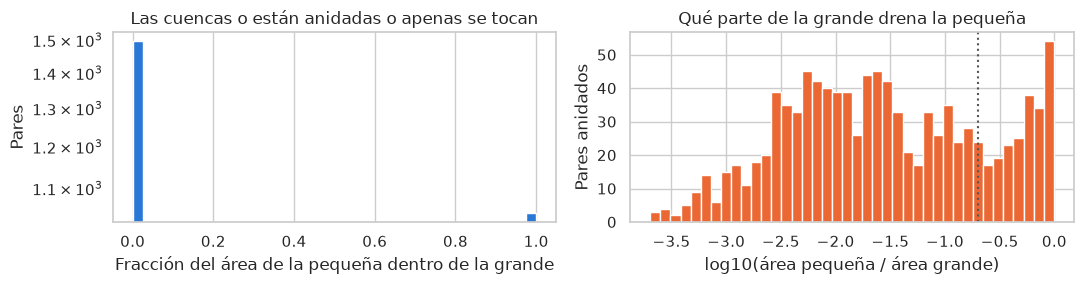

In [6]:
ids = list(est.index)
poli = val.poligonos(ids)
pares = val.pares_anidados(poli)
dentro = pares[pares.frac_dentro > .5]
print(f"Pares de cuencas que se tocan: {len(pares):,}   anidadas (> 50 % dentro): {len(dentro):,}   "
      f"cuencas que contienen o están dentro de otra: {len(set(dentro.grande) | set(dentro.pequena))} de {len(ids)}")
print(f"Pares con solapamiento parcial (1 %–95 %): {int(pares.frac_dentro.between(.01, .95).sum())}")
g_todo = val.grupos_conectados(ids, dentro)
print(f"Si se agrupa toda cuenca conectada: {g_todo.nunique()} grupos; el mayor tiene {int(g_todo.value_counts().iloc[0])} cuencas "
      f"({region[g_todo[g_todo == 0].index].value_counts().to_dict()})")
fig, ax = plt.subplots(1, 2, figsize=(11, 3))
ax[0].hist(pares.frac_dentro, bins=40, color="#2a78d6"); ax[0].set(yscale="log", xlabel="Fracción del área de la pequeña dentro de la grande", ylabel="Pares", title="Las cuencas o están anidadas o apenas se tocan")
ax[1].hist(np.log10(dentro.rel_area), bins=40, color="#eb6834"); ax[1].axvline(np.log10(val.UMBRAL_ANIDADA), color="#555", ls=":")
ax[1].set(xlabel="log10(área pequeña / área grande)", ylabel="Pares anidados", title="Qué parte de la grande drena la pequeña")
fig.tight_layout(); fig.savefig(OUT / "fig_cuencas_anidadas.png", dpi=200); plt.show()

**Lectura.** Los polígonos no dejan dudas: cada par o está anidado (más del 95 % del área de la pequeña dentro de la grande) o apenas comparte el borde. Hay 1.044 pares anidados. Pero agrupar **toda** cuenca conectada, como proponía el primer reporte ("sistemas de ríos completos"), **no es viable**: las estaciones del Magdalena y el Cauca contienen a casi todas las demás de la región y forman un solo grupo de 130 cuencas, más de la mitad de los datos. Con un grupo así no se pueden armar 5 folds parecidos.

### 3b. Cuándo dos cuencas anidadas deben ir juntas
Lo que filtra información no es que dos cuencas estén conectadas, sino **cuánto comparten**. Si una cuenca de 50 km² está dentro de una de 50.000 km², sus caudales casi no se parecen. Si la pequeña es la mitad de la grande, sí. Se unen en un mismo grupo solo los pares en que la pequeña es al menos una fracción $u$ del área de la grande, y se mide qué queda compartido entre entrenamiento y evaluación:
- **aguas arriba**: fracción del área de la cuenca evaluada drenada por cuencas de entrenamiento que están dentro de ella.
- **aguas abajo**: la mayor fracción que la cuenca evaluada representa de una cuenca de entrenamiento que la contiene.

Para comparar umbrales se usan los folds de la semilla 42; la semilla definitiva se escoge en 3c.

In [7]:
tu = val.resumen_umbral(ids, region, poli, pares, [0.05, 0.1, 0.2, 0.3, 0.5, 1.01])
display(tu.rename(index={1.01: "sin agrupar"}).round(3))

,grupos,grupo más grande,cuencas por fold (mín-máx),aguas arriba mediana,aguas arriba p90,"cuencas con aguas arriba >= 0,5","cuencas con aguas abajo >= 0,2"
umbral rel_area,,,,,,,
0.05,103,61,40-75,0.0,0.054,0,0
0.1,122,46,43-63,0.0,0.102,0,0
0.2,146,12,48-51,0.0,0.204,1,0
0.3,156,12,49-51,0.0,0.245,2,9
0.5,183,10,49-50,0.0,0.427,13,38
sin agrupar,248,1,49-51,0.0,0.881,66,92


**Lectura.** Con $u$ pequeño los grupos crecen y los folds se desequilibran (con 0,05 un fold tiene 40 cuencas y otro 75). Sin agrupar, 66 cuencas tendrían más de la mitad de su área drenada por cuencas de entrenamiento, y 92 serían al menos el 20 % de una cuenca de entrenamiento que las contiene.

**Decisión: $u$ = 0,2.** Es el menor umbral con el que el grupo más grande queda en 12 cuencas (5 %) y los folds quedan parejos (48 a 51 cuencas). Con este umbral solo **una** cuenca evaluada tiene más de la mitad de su área drenada por cuencas de entrenamiento, el percentil 90 de esa fracción es 0,2, y ninguna cuenca evaluada es el 20 % o más de una cuenca de entrenamiento que la contenga.

### 3c. Los 5 folds
`StratifiedGroupKFold` de scikit-learn no parte ningún grupo y reparte las regiones de forma pareja entre folds. Se definen semillas para poder reproducir la ejecución, pero con algunas semillas un fold puede quedar con cuencas más bajas o más boscosas que el resto. Por eso se generan 50 particiones con semillas distintas y se escoge la de menor desequilibrio: el mayor estadístico KS entre las cuencas de un fold y las 248, sobre cuatro atributos (aridez, área, elevación media y bosque). **El criterio no usa el caudal ni ningún modelo**, y se fija antes de entrenar; el caudal medio queda como control independiente en la sección 4b.

KS máximo según la semilla: mejor 0.173 (semilla 4), mediana 0.247, peor 0.347; con la semilla 42 sería 0.323


,KS_max,KS_medio,cuencas_min,cuencas_max
semilla,,,,
4,0.173,0.122,48,51
6,0.181,0.118,48,51
30,0.192,0.118,48,51
14,0.205,0.122,48,51
38,0.205,0.126,48,51


region,Magdalena-Cauca,Orinoco,Caribe,Pacífico,Amazonas,total
fold,,,,,,
0,27,7,9,4,2,49
1,27,7,9,3,3,49
2,28,6,9,3,2,48
3,27,10,9,3,2,51
4,27,7,8,7,2,51
total,136,37,44,20,11,248


Grupos: 146  (cuencas solas: 112; el mayor: 12)


,count,mean,std,min,50%,90%,95%,max
aguas_arriba,248.0,0.049,0.104,0.0,0.000,0.208,0.253,0.556
aguas_abajo,248.0,0.033,0.051,0.0,0.006,0.124,0.158,0.198


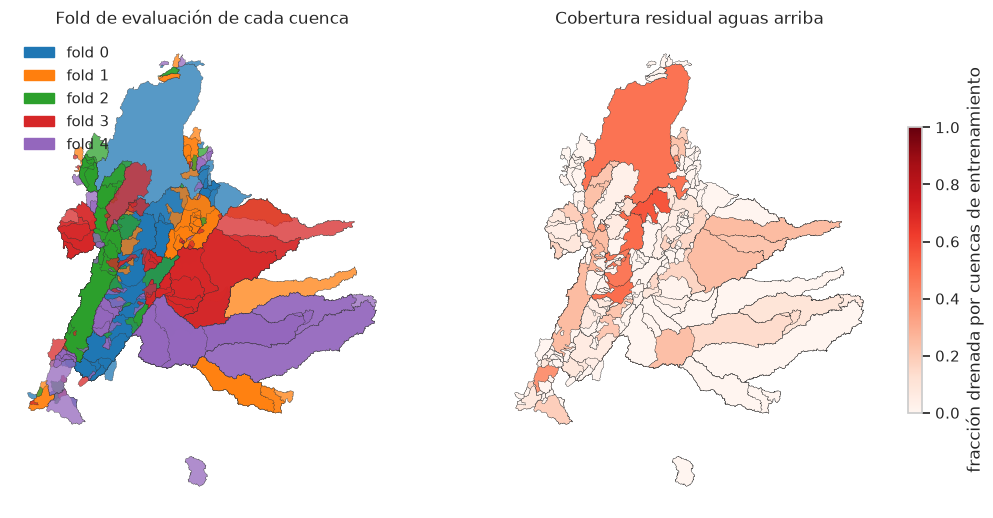

In [8]:
grupo = val.grupos_conectados(ids, val.enlaces(pares))
sem = val.escoger_semilla(grupo, region, est[["aridez", "log_area", "mean_ele", "forest_perc"]])
SEMILLA_FOLDS = int(sem.index[0])
print(f"KS máximo según la semilla: mejor {sem.KS_max.min():.3f} (semilla {SEMILLA_FOLDS}), mediana {sem.KS_max.median():.3f}, "
      f"peor {sem.KS_max.max():.3f}; con la semilla 42 sería {sem.loc[42, 'KS_max']:.3f}")
display(sem.head(5).round(3))
fold = val.folds_espaciales(grupo, region, semilla=SEMILLA_FOLDS)
cob = val.cobertura_residual(poli, pares, fold)
display(pd.crosstab(fold, region, margins=True, margins_name="total")[ORDEN + ["total"]])
print(f"Grupos: {grupo.nunique()}  (cuencas solas: {int((grupo.value_counts() == 1).sum())}; el mayor: {int(grupo.value_counts().iloc[0])})")
display(cob.describe(percentiles=[.5, .9, .95]).T.round(3))

fig, ax = plt.subplots(1, 2, figsize=(11, 5.5))
mapa = poli.join(fold).join(cob).sort_values("area_km2", ascending=False)
pal = sns.color_palette("tab10", val.N_FOLDS)
for f in range(val.N_FOLDS):
    mapa[mapa.fold == f].plot(ax=ax[0], color=pal[f], edgecolor="#333", lw=.2, alpha=.75, label=f"fold {f}")
ax[0].set(title="Fold de evaluación de cada cuenca"); ax[0].set_axis_off()
ax[0].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=pal[f]) for f in range(val.N_FOLDS)], labels=[f"fold {f}" for f in range(val.N_FOLDS)], frameon=False, loc="upper left")
mapa.plot(ax=ax[1], column="aguas_arriba", cmap="Reds", vmin=0, vmax=1, edgecolor="#333", lw=.2, legend=True, legend_kwds={"shrink": .6, "label": "fracción drenada por cuencas de entrenamiento"})
ax[1].set(title="Cobertura residual aguas arriba"); ax[1].set_axis_off()
fig.tight_layout(); fig.savefig(OUT / "fig_folds_espaciales.png", dpi=200); plt.show()

**Lectura.** La semilla importa: el mayor KS entre un fold y el total va de 0,17 a 0,35 según la semilla (0,32 con la semilla 42, que dejaba un fold más bajo y más boscoso que el resto). Se usa la **semilla 4**, la de menor desequilibrio. Los 5 folds tienen entre 48 y 51 cuencas y la misma mezcla de regiones (27–28 de Magdalena-Cauca, 8–9 del Caribe, 6–10 del Orinoco, 3–7 del Pacífico y 2–3 del Amazonas). La cobertura residual es baja: la mediana es 0, el percentil 90 es 0,21, solo una cuenca pasa de 0,5 (0,56) y ninguna cuenca evaluada es el 20 % o más de una cuenca de entrenamiento que la contiene.

**Para el informe.** El Amazonas tiene 2 o 3 cuencas por fold y el Pacífico 3 a 7; la mediana regional de P6 en esas regiones es frágil y se debe presentar con el número de cuencas. Al reportar P6 conviene dar también la mediana del NSE en las cuencas con cobertura aguas arriba menor que 0,05, las más parecidas a una cuenca sin ninguna estación cerca.

## 4. ¿Se conservan las distribuciones?
Se va a comparar cada subconjunto **con el conjunto original**. Se usan dos medidas de tamaño del cambio, no pruebas de hipótesis: con millones de filas cualquier diferencia mínima da un valor p cercano a cero.
- **Estadístico KS** ($D$): la mayor distancia entre las dos distribuciones acumuladas. $D$ = 0,05 quiere decir que, para cualquier valor, la proporción de filas por debajo de él difiere a lo sumo 5 puntos porcentuales.
- **PSI** (índice de estabilidad poblacional): $\sum_i (s_i - t_i)\ln(s_i/t_i)$ sobre los deciles del conjunto total. Regla usual [3]: < 0,1 sin cambio, 0,1–0,25 cambio moderado, > 0,25 cambio grande.

### 4a. Partición temporal (filas)

n    media      p05  mediana       p95     KS  \
variable subconjunto                                                          
q        total          2483808    3.549    0.412    2.341    10.481  0.000   
         entrenamiento  1566789    3.488    0.411    2.296    10.261  0.010   
         validacion      456597    3.749    0.462    2.543    10.810  0.037   
         prueba          460422    3.558    0.377    2.308    10.817  0.012   
P        total          2483808    5.949    0.000    1.851    24.289  0.000   
         entrenamiento  1566789    5.913    0.000    1.953    23.886  0.006   
         validacion      456597    6.201    0.000    1.792    25.543  0.011   
         prueba          460422    5.823    0.000    1.580    24.301  0.016   
P30      total          2483808  178.052   32.860  155.550   399.831  0.000   
         entrenamiento  1566789  177.138   33.074  154.632   398.992  0.005   
         validacion      456597  185.023   33.531  162.857   411.320  0.027   
         prueba          460422  174.249   31.510  151.980   390.699  0.013   
P90      total          2483808  532.210  164.060  471.055  1098.521  0.000   
         entrenamiento  1566789  530.480  166.117  468.101  1099.401  0.005   
         validacion      456597  552.754  166.704  492.978  1120.097  0.035   
         prueba          460422  517.722  154.876  459.510  1071.951  0.020   
Tmean    total          2483808   18.597   10.781   18.590    26.901  0.000   
         entrenamiento  1566789   18.365   10.625   18.330    26.609  0.023   
         validacion      456597   18.897   10.984   18.907    27.240  0.029   
         prueba          460422   19.089   10.984   19.188    27.420  0.052   
ETP      total          2483808    3.283    2.248    3.257     4.425  0.000   
         entrenamiento  1566789    3.252    2.227    3.227     4.371  0.018   
         validacion      456597    3.333    2.294    3.309     4.464  0.032   
         prueba          460422    3.342    2.284    3.306     4.546  0.032   

                          PSI  
variable subconjunto           
q        total          0.000  
         entrenamiento  0.001  
         validacion     0.007  
         prueba         0.002  
P        total          0.000  
         entrenamiento  0.000  
         validacion     0.002  
         prueba         0.001  
P30      total          0.000  
         entrenamiento  0.000  
         validacion     0.004  
         prueba         0.001  
P90      total          0.000  
         entrenamiento  0.000  
         validacion     0.006  
         prueba         0.003  
Tmean    total          0.000  
         entrenamiento  0.003  
         validacion     0.006  
         prueba         0.014  
ETP      total          0.000  
         entrenamiento  0.002  
         validacion     0.006  
         prueba         0.007

KS máximo: 0.052   PSI máximo: 0.014


,"KS máximo (q, P30)","PSI máximo (q, P30)"
Magdalena-Cauca,0.054,0.015
Orinoco,0.033,0.014
Caribe,0.038,0.009
Pacífico,0.033,0.012
Amazonas,0.046,0.020


,total,entrenamiento,validacion,prueba
% de filas por región,,,,
Magdalena-Cauca,59.4,59.8,58.6,58.4
Orinoco,15.1,14.5,15.8,16.3
Caribe,14.6,14.9,14.6,13.8
Pacífico,7.1,7.1,7.0,7.3
Amazonas,3.8,3.7,3.9,4.1


Proporción de filas por mes: diferencia máxima con el total = 0.48 puntos porcentuales


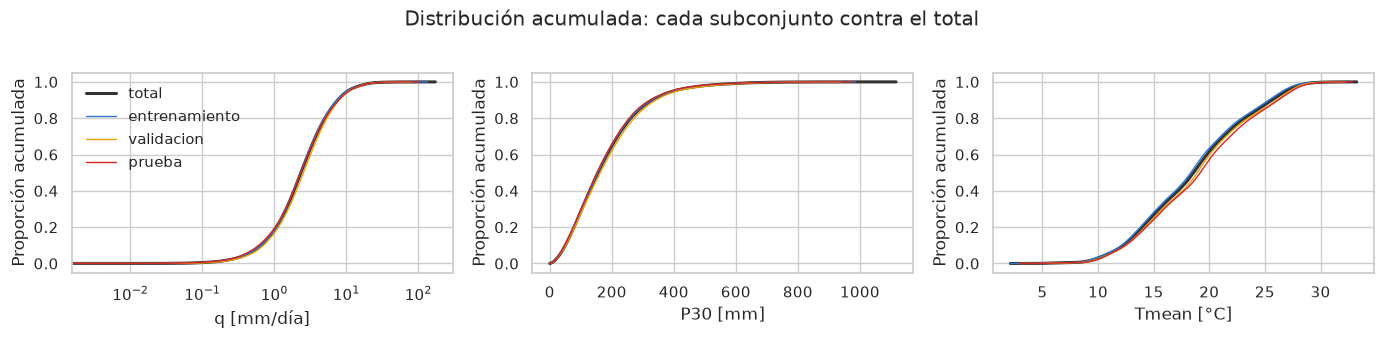

In [9]:
VARS = ["q", "P", "P30", "P90", "Tmean", "ETP"]
dt = val.comparar_con_total(filas, "particion", VARS)
display(dt.round(3))
print(f"KS máximo: {dt.KS.max():.3f}   PSI máximo: {dt.PSI.max():.3f}")

por_region = []
for r in ORDEN:
    x = val.comparar_con_total(filas[filas.region == r], "particion", ["q", "P30"]).drop("total", level=1)
    por_region.append(x[["KS", "PSI"]].max().rename(r))
display(pd.DataFrame(por_region).round(3).rename(columns={"KS": "KS máximo (q, P30)", "PSI": "PSI máximo (q, P30)"}))

prop = pd.concat({"total": filas.region.value_counts(normalize=True)} |
                 {p: filas.loc[filas.particion == p, "region"].value_counts(normalize=True) for p in val.PERIODOS}, axis=1).loc[ORDEN]
display((100 * prop).round(1).rename_axis("% de filas por región"))
mes = pd.crosstab(filas.particion, filas.Fecha.dt.month, normalize="index")
print("Proporción de filas por mes: diferencia máxima con el total =",
      f"{100 * (mes - filas.Fecha.dt.month.value_counts(normalize=True).sort_index()).abs().max().max():.2f} puntos porcentuales")

fig, ax = plt.subplots(1, 3, figsize=(14, 3.3))
for a, v, t in zip(ax, ["q", "P30", "Tmean"], ["q [mm/día]", "P30 [mm]", "Tmean [°C]"]):
    x = np.sort(filas[v].to_numpy()); a.plot(x[::200], np.linspace(0, 1, len(x))[::200], color="#333", lw=2.2, label="total")
    for p in val.PERIODOS:
        x = np.sort(filas.loc[filas.particion == p, v].to_numpy()); a.plot(x[::50], np.linspace(0, 1, len(x))[::50], color=COLOR_P[p], lw=1, label=p)
    a.set(xlabel=t, ylabel="Proporción acumulada", xscale="log" if v == "q" else "linear")
ax[0].legend(frameon=False); fig.suptitle("Distribución acumulada: cada subconjunto contra el total", y=1.02)
fig.tight_layout(); fig.savefig(OUT / "fig_distribucion_temporal.png", dpi=200, bbox_inches="tight"); plt.show()

**Lectura.** **Las distribuciones se conservan.** En las seis variables y los tres subconjuntos el KS es como mucho 0,052 y el PSI como mucho 0,014, muy por debajo de 0,1. Dentro de cada región el KS no pasa de 0,054 ni el PSI de 0,020. Los atributos de las cuencas son idénticos en los tres conjuntos porque las 248 cuencas están en todos. La proporción de filas por región cambia a lo sumo 1,2 puntos porcentuales y la de filas por mes 0,5 puntos.

Las diferencias que sí aparecen son físicas y pequeñas: la validación es algo más húmeda (q mediano 2,54 frente a 2,34 mm/día del total) y la prueba es medio grado más cálida (Tmean media 19,1 frente a 18,6 °C), lo esperable si la prueba cae en los años más recientes. Hay que mencionarlo al interpretar el desempeño en prueba.

### 4b. Partición espacial (cuencas)
En la validación espacial la unidad es la cuenca, así que se comparan atributos por cuenca, las cuencas de cada fold contra las 248. Con ~50 cuencas por fold el valor p de KS sí es informativo.

"valor p de KS, fold",0,1,2,3,4
atributo,,,,,
aridez,0.234,0.685,0.157,0.757,0.589
bosque [%],0.842,0.730,0.857,0.174,0.153
elevación media [m],0.448,0.612,0.228,0.664,0.347
log(área),0.966,0.755,0.626,0.518,0.739
q medio [mm/día],0.965,0.552,0.890,0.435,0.446


Comparaciones con p < 0,05: 0 de 25 (por azar se esperarían 1)


,atributo,fold,mediana_fold,mediana_total,KS,p


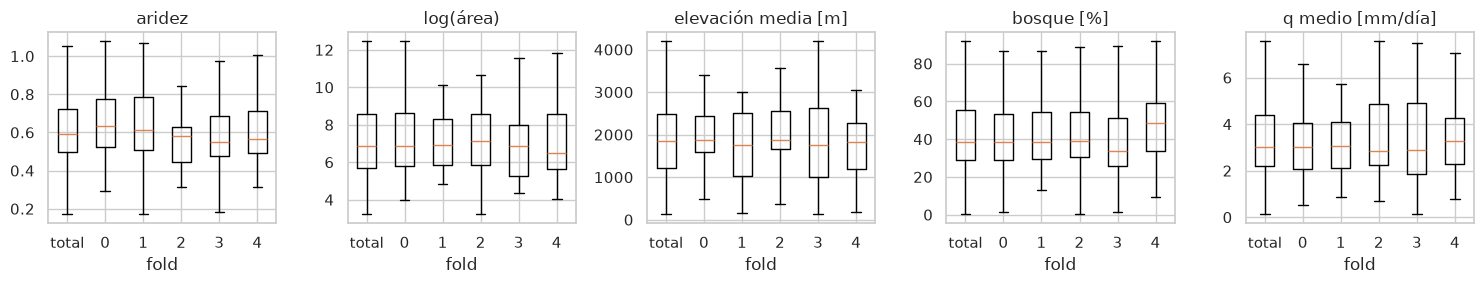

In [10]:
ATR = {"aridez": "aridez", "log_area": "log(área)", "mean_ele": "elevación media [m]", "forest_perc": "bosque [%]", "q_medio": "q medio [mm/día]"}
cu = est[["aridez", "log_area", "mean_ele", "forest_perc"]].copy()
cu["q_medio"] = filas.groupby("gauge_id").q.mean()
cu["fold"] = fold
fe = []
for v, nombre in ATR.items():
    for f in range(val.N_FOLDS):
        x = cu.loc[cu.fold == f, v]; r = stats.ks_2samp(x, cu[v])
        fe.append(dict(atributo=nombre, fold=f, mediana_fold=x.median(), mediana_total=cu[v].median(), KS=r.statistic, p=r.pvalue))
fe = pd.DataFrame(fe)
display(fe.pivot(index="atributo", columns="fold", values="p").round(3).rename_axis(columns="valor p de KS, fold"))
print(f"Comparaciones con p < 0,05: {int((fe.p < .05).sum())} de {len(fe)} (por azar se esperarían {0.05 * len(fe):.0f})")
display(fe[fe.p < .05].round(3))

fig, ax = plt.subplots(1, len(ATR), figsize=(15, 3))
for a, (v, nombre) in zip(ax, ATR.items()):
    datos = [cu[v]] + [cu.loc[cu.fold == f, v] for f in range(val.N_FOLDS)]
    a.boxplot(datos, tick_labels=["total"] + [str(f) for f in range(val.N_FOLDS)], showfliers=False)
    a.set(title=nombre, xlabel="fold")
fig.tight_layout(); fig.savefig(OUT / "fig_distribucion_espacial.png", dpi=200); plt.show()

**Lectura.** **Los folds representan bien al conjunto de cuencas.** Ninguna de las 25 comparaciones (5 atributos × 5 folds) da p < 0,05 y el menor valor p es 0,15. El caudal medio, que no entró al criterio de la semilla, también se conserva (p ≥ 0,43), y la región está equilibrada por construcción (3c). Además, en una validación cruzada cada cuenca se evalúa exactamente una vez, así que el conjunto de cuencas evaluadas en P6 es el conjunto original completo.

## 5. Estrategia de selección del modelo

**Algoritmos y grillas** propuestos, con su respectivo espacio de hiperparámetros:

| Algoritmo | Hiperparámetros | Configuraciones |
|---|---|---|
| Regresión lineal con regularización (Ridge), línea base | `alpha` ∈ {0,1; 1; 10; 100} | 4 |
| Random Forest | `max_depth` ∈ {10, 20, None}, `min_samples_leaf` ∈ {5, 20, 100}, `max_features` ∈ {0,33; 0,66}; 300 árboles | 18 |
| Gradient boosting (`HistGradientBoostingRegressor`) | `learning_rate` ∈ {0,05; 0,1}, `max_leaf_nodes` ∈ {31, 127}, `min_samples_leaf` ∈ {20, 200}, `l2_regularization` ∈ {0, 1} | 16 |
| LSTM regional (solo si los docentes lo aprueban) | unidades ∈ {64, 128}, dropout ∈ {0,2; 0,4}; secuencia de 365 días | 4 |

**Protocolo.** Todo modelo es un `Pipeline` con el preprocesamiento de `pdat.crear_preprocesamiento`, así que la imputación y la escala se ajustan solo con los datos de entrenamiento de cada corrida.
1. **Hiperparámetros**: cada configuración se entrena con *entrenamiento* y se califica en *validación* con la **mediana del NSE por cuenca** (`val.buscar_hiperparametros`). Es lo mismo que `GridSearchCV` con `PredefinedSplit`, pero el puntaje de `GridSearchCV` mezcla todas las filas, y ese R² o error conjunto lo dominan las cuencas húmedas. Para el Random Forest y el boosting la búsqueda puede usar hasta 2.000 días de entrenamiento por cuenca (`construir_filas(..., n_por_cuenca_train=2000)`).
2. **Algoritmo**: con la mejor configuración de cada uno se corre la validación cruzada espacial, entrenando con el periodo de entrenamiento de 4 folds y evaluando el periodo de validación del fold que queda fuera (`val.evaluar_espacial(..., periodo_eval="validacion")`). **Se escoge el algoritmo con mayor NSE mediano espacial**, porque el uso principal del producto son las cuencas sin estación. El NSE temporal de validación desempata; si dos algoritmos difieren en menos de 0,02, se prefiere el más simple.
3. **Prueba, una sola vez**: con la elección congelada, se reentrena con *entrenamiento + validación* y se reportan sobre el periodo de *prueba*: el KPI temporal (P4), la validación espacial (P6, con `periodos_entrenamiento=("entrenamiento", "validacion")` y `periodo_eval="prueba"`) y las comparaciones P5 (t-test pareado del NSE por cuenca) y P7 (ANOVA por región). Si después de mirar la prueba se cambia algo, la prueba deja de ser independiente y hay que decirlo.

**Métricas** (por cuenca, resumidas con la mediana nacional y por región [4]): NSE y KGE (1 es perfecto; NSE ≤ 0 no mejora al caudal medio), RMSE y MAE en mm/día. Para crecientes (P9): recall y precisión en los días por encima del percentil 95 de cada cuenca, con el umbral calculado en el periodo de entrenamiento.

### 5a. Línea base con el protocolo
La regresión Ridge recorre los pasos 1 y 2. Sirve para comprobar que el protocolo funciona y deja la referencia del KPI "el mejor modelo supera a la regresión lineal" sin tocar la prueba.

In [11]:
tr, va = X[X.particion == "entrenamiento"], X[X.particion == "validacion"]
ridge = Pipeline([("pre", pdat.crear_preprocesamiento(col_num, col_cat)), ("modelo", Ridge())])
busq = val.buscar_hiperparametros(ridge, {"modelo__alpha": [0.1, 1, 10, 100]}, tr[COLS], tr.q, va[COLS], va.q, va.gauge_id)
display(busq.round(4))
mejor = ridge.set_params(**{"modelo__alpha": busq.iloc[0]["modelo__alpha"]})

met_t = pdat.metricas_por_cuenca(va.gauge_id, va.q, mejor.fit(tr[COLS], tr.q).predict(va[COLS]))
met_e = val.evaluar_espacial(mejor, X, fold, COLS, periodo_eval="validacion")
lb = pd.concat({"temporal (cuencas vistas)": val.resumir(met_t, region), "espacial (cuencas no vistas)": val.resumir(met_e.drop(columns="fold"), region)}, axis=1)
display(lb.loc[ORDEN + ["Nacional"]].round(3))
sin_vecinas = cob.index[cob.aguas_arriba < .05]
print(f"NSE mediano espacial en las {len(sin_vecinas)} cuencas con cobertura aguas arriba < 0,05: {met_e.loc[sin_vecinas].NSE.median():.3f} "
      f"(área mediana {areas[sin_vecinas].median():,.0f} km² frente a {areas.drop(sin_vecinas).median():,.0f} km² del resto; "
      f"{100 * (~sin_vecinas.isin(dentro.grande)).mean():.0f} % no contiene ninguna otra estación)")
met_t.join(met_e.add_suffix("_espacial")).to_csv(OUT / "linea_base_ridge_validacion.csv")

,modelo__alpha,NSE mediano,KGE mediano,cuencas con NSE > 0
1,1.0,0.2530,0.4021,191
3,100.0,0.2528,0.4019,191
2,10.0,0.2526,0.4019,191
0,0.1,0.2508,0.4029,190


temporal (cuencas vistas)                               \
                                      NSE    KGE   RMSE    MAE cuencas   
region                                                                   
Magdalena-Cauca                     0.223  0.387  1.854  1.257     136   
Orinoco                             0.466  0.538  1.961  1.342      37   
Caribe                              0.185  0.378  2.751  1.867      44   
Pacífico                            0.319  0.485  1.946  1.477      20   
Amazonas                            0.327  0.349  2.730  1.804      11   
Nacional                            0.253  0.402  1.952  1.342     248   

                espacial (cuencas no vistas)                               
                                         NSE    KGE   RMSE    MAE cuencas  
region                                                                     
Magdalena-Cauca                        0.180  0.366  1.976  1.341     136  
Orinoco                                0.412  0.440  2.090  1.591      37  
Caribe                                 0.130  0.363  3.099  2.070      44  
Pacífico                               0.143  0.448  2.284  1.630      20  
Amazonas                               0.296  0.345  3.385  2.050      11  
Nacional                               0.215  0.374  2.138  1.517     248

NSE mediano espacial en las 190 cuencas con cobertura aguas arriba < 0,05: 0.170 (área mediana 618 km² frente a 18,287 km² del resto; 73 % no contiene ninguna otra estación)


**Lectura.** Con esta cantidad de filas la regularización casi no cambia nada (las cuatro `alpha` quedan entre 0,251 y 0,253); la búsqueda está para mostrar el mecanismo. La línea base deja un NSE mediano de validación de **0,25 en cuencas vistas y 0,22 en cuencas no vistas**, lejos de las metas de 0,70 y 0,50: hay espacio para que los modelos no lineales del ítem 10 muestren su aporte. El Orinoco es la región que mejor se estima en los dos casos (0,47 y 0,41) y el Caribe la peor (0,19 y 0,13).

Dos cosas para el reporte de P6:
- En las 190 cuencas sin cuencas de entrenamiento aguas arriba (cobertura < 0,05) el NSE mediano espacial baja a 0,17. Esas cuencas son en su mayoría cabeceras pequeñas (área mediana de unos 620 km² frente a 18.300 km² del resto, y el 73 % no contiene ninguna otra estación), más difíciles por sí mismas, pero también son el caso más parecido a una cuenca sin ninguna estación cerca, así que la cifra debe ir junto a la mediana general.
- El resultado espacial depende de cómo caen las cuencas en los folds: con la semilla 42 la misma línea base daba 0,18 en vez de 0,22. Conviene repetir la validación espacial del modelo final con dos o tres semillas más y reportar el rango.

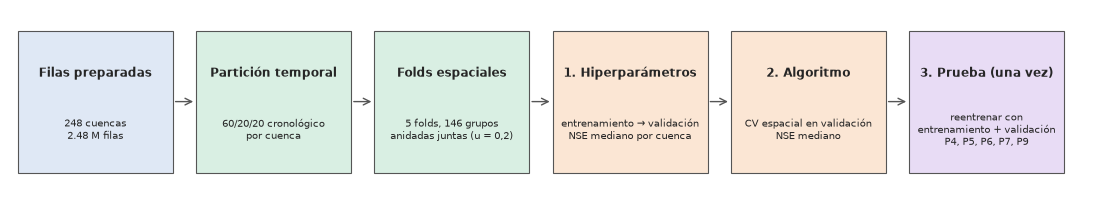

In [12]:
pasos = [("Filas preparadas", f"{len(est)} cuencas\n{len(filas)/1e6:.2f} M filas", "#dfe8f5"),
         ("Partición temporal", "60/20/20 cronológico\npor cuenca", "#d9efe3"),
         ("Folds espaciales", f"{val.N_FOLDS} folds, {grupo.nunique()} grupos\nanidadas juntas (u = {str(val.UMBRAL_ANIDADA).replace('.', ',')})", "#d9efe3"),
         ("1. Hiperparámetros", "entrenamiento → validación\nNSE mediano por cuenca", "#fbe6d4"),
         ("2. Algoritmo", "CV espacial en validación\nNSE mediano", "#fbe6d4"),
         ("3. Prueba (una vez)", "reentrenar con\nentrenamiento + validación\nP4, P5, P6, P7, P9", "#e8dcf5")]
fig, ax = plt.subplots(figsize=(14, 2.4)); ax.axis("off")
for i, (t, sub, c) in enumerate(pasos):
    x = i * 2.3
    ax.add_patch(plt.Rectangle((x, 0.15), 2.0, 1.0, fc=c, ec="#555", lw=.8))
    ax.text(x + 1.0, .85, t, ha="center", va="center", fontsize=8.5, weight="bold"); ax.text(x + 1.0, .45, sub, ha="center", va="center", fontsize=7.2)
    if i < len(pasos) - 1: ax.annotate("", xy=(x + 2.3, .65), xytext=(x + 2.0, .65), arrowprops=dict(arrowstyle="->", color="#555"))
ax.set_xlim(-.1, 13.9); ax.set_ylim(0, 1.3)
fig.savefig(OUT / "fig_protocolo_seleccion.png", dpi=200, bbox_inches="tight"); plt.show()

## 6. Archivos para el modelado
Las filas no se guardan (se rehacen en segundos con `pdat.construir_filas`). Se guarda lo que define la partición, para que todos los modelos usen exactamente la misma.

In [13]:
fc.join(region).to_csv(OUT / "fechas_corte.csv")
pd.concat([region, grupo, fold, cob], axis=1).rename_axis("gauge_id").to_csv(OUT / "folds_espaciales.csv")
print(f"Folds escritos con la semilla {SEMILLA_FOLDS}")
dentro.to_csv(OUT / "cuencas_anidadas.csv", index=False)
dt.to_csv(OUT / "distribucion_temporal.csv")
fe.to_csv(OUT / "distribucion_espacial.csv", index=False)
for p in sorted(OUT.iterdir()):
    print(f"{p.relative_to(RAIZ)}")

Folds escritos con la semilla 4
salidas/particion/cuencas_anidadas.csv
salidas/particion/distribucion_espacial.csv
salidas/particion/distribucion_temporal.csv
salidas/particion/fechas_corte.csv
salidas/particion/fig_autocorrelacion.png
salidas/particion/fig_cuencas_anidadas.png
salidas/particion/fig_distribucion_espacial.png
salidas/particion/fig_distribucion_temporal.png
salidas/particion/fig_folds_espaciales.png
salidas/particion/fig_particion_temporal.png
salidas/particion/fig_protocolo_seleccion.png
salidas/particion/fig_prueba_fecha_fija.png
salidas/particion/folds_espaciales.csv
salidas/particion/linea_base_ridge_validacion.csv


Uso en el notebook de modelado:
```python
filas, _ = pdat.construir_filas(est, areas)                     # trae la columna `particion`
X = pdat.agregar_estaticos(filas, est)
fold = pd.read_csv(RAIZ / "salidas/particion/folds_espaciales.csv", dtype={"gauge_id": str}).set_index("gauge_id").fold
busq = val.buscar_hiperparametros(modelo, grilla, X_tr, y_tr, X_val, y_val, g_val)                 # paso 1
met_e = val.evaluar_espacial(mejor, X, fold, COLS, periodo_eval="validacion")                     # paso 2
met_p6 = val.evaluar_espacial(mejor, X, fold, COLS, periodo_eval="prueba",
                              periodos_entrenamiento=("entrenamiento", "validacion"))             # paso 3 (una vez)
```